# K-Means Clustering

This notebook performs K-Means clustering on `clustering_patients.csv`, evaluates cluster quality, and produces the elbow curve, PCA visualization, and t-SNE visualization.


## 1. Import libraries

In [13]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## 2. Load dataset

In [14]:
DATA_PATH = "../dataset/clustering_patients.csv"
if not os.path.exists(DATA_PATH):
    if os.path.exists("dataset/clustering_patients.csv"):
        DATA_PATH = "dataset/clustering_patients.csv"
    elif os.path.exists("/mnt/data/clustering_patients(3).csv"):
        DATA_PATH = "/mnt/data/clustering_patients(3).csv"
    elif os.path.exists("/mnt/data/clustering_patients.csv"):
        DATA_PATH = "/mnt/data/clustering_patients.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1650, 5)


,age,blood_pressure_sys,cholesterol,sodium_potassium_ratio,heart_rate
0,33,171,239,17.13,98
1,39,132,251,13.79,105
2,24,120,181,19.10,63
3,26,124,201,19.47,77
4,73,137,157,11.65,82


## 3. Dataset overview

In [15]:
df.info()
print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))
print("\\nDuplicate rows:", df.duplicated().sum())
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 1650 entries, 0 to 1649
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     1650 non-null   int64  
 1   blood_pressure_sys      1650 non-null   int64  
 2   cholesterol             1650 non-null   int64  
 3   sodium_potassium_ratio  1634 non-null   float64
 4   heart_rate              1650 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 64.6 KB
\nMissing values:


,Missing Values
age,0
blood_pressure_sys,0
cholesterol,0
sodium_potassium_ratio,16
heart_rate,0


\nDuplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,1650.0,48.204848,20.291280,15.0,30.00,47.000,66.00,84.00
blood_pressure_sys,1650.0,134.185455,25.602779,90.0,112.00,133.000,157.00,179.00
cholesterol,1650.0,217.416364,56.731732,120.0,170.00,216.000,265.75,319.00
sodium_potassium_ratio,1634.0,16.826506,5.981947,5.0,12.63,16.815,21.12,37.62
heart_rate,1650.0,84.138788,14.372064,60.0,72.00,84.000,97.00,109.00


## 4. Handle missing values and scale features

In [16]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
if len(numeric_columns) != df.shape[1]:
    print("Warning: non-numeric columns are excluded from clustering.")

X_raw = df[numeric_columns].copy()
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X_raw), columns=numeric_columns, index=df.index)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Missing values after imputation:", int(X_imputed.isnull().sum().sum()))
print("Scaled matrix shape:", X_scaled.shape)

Missing values after imputation: 0
Scaled matrix shape: (1650, 5)


## 5. Exploratory data analysis

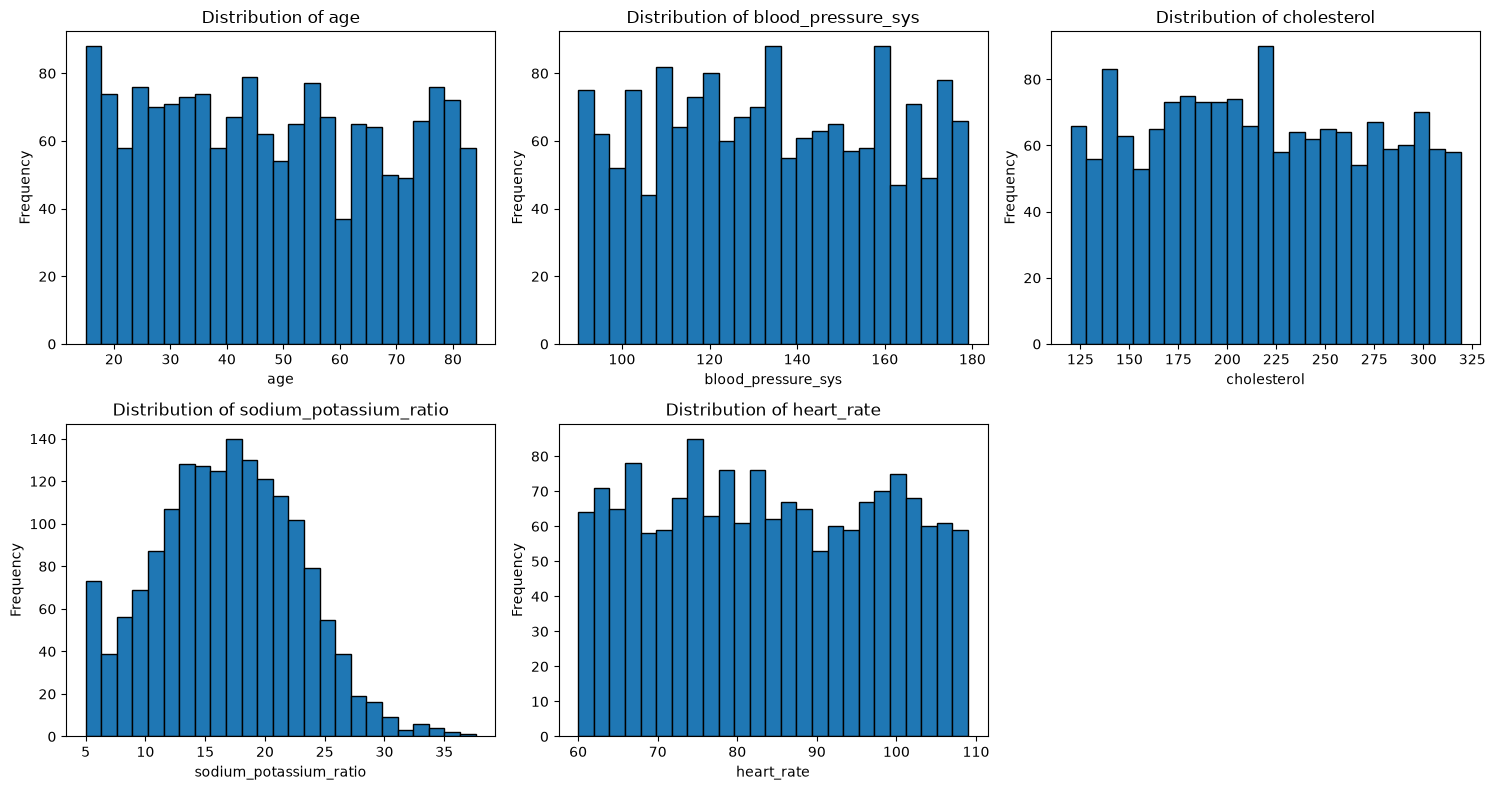

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(numeric_columns):
    axes[i].hist(X_imputed[col], bins=25, edgecolor="black")
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")
for j in range(len(numeric_columns), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

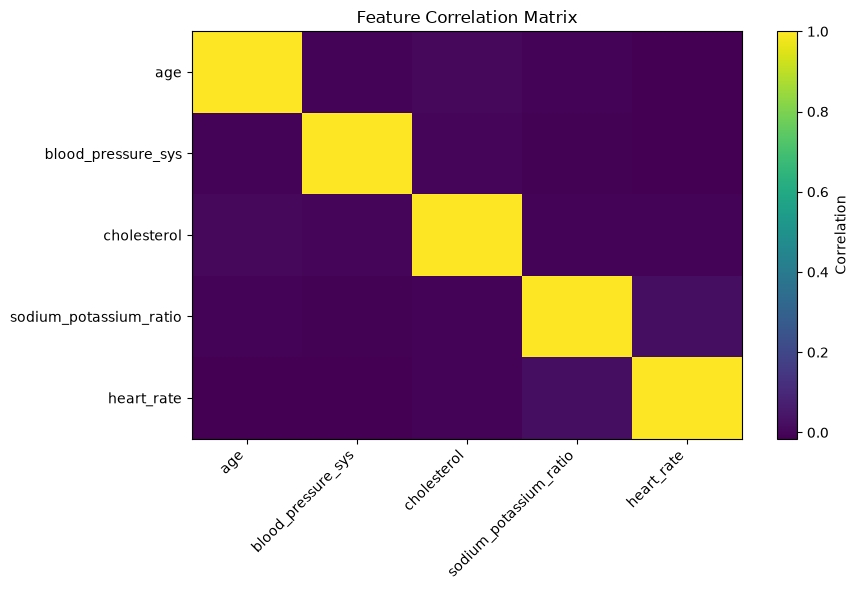

In [18]:
plt.figure(figsize=(9, 6))
corr = X_imputed.corr()
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_columns)), numeric_columns, rotation=45, ha="right")
plt.yticks(range(len(numeric_columns)), numeric_columns)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 6. Select cluster count using the Elbow Method

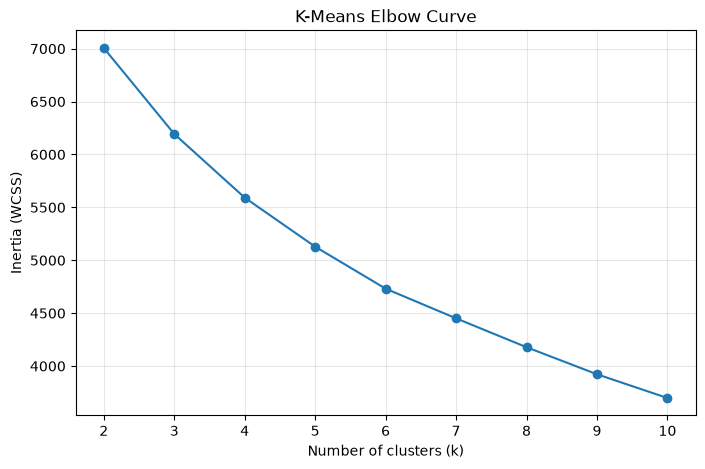

In [19]:
inertias = []
k_values = range(2, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("K-Means Elbow Curve")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

## 7. Fit K-Means

In [20]:
# Review the elbow curve and change N_CLUSTERS if needed.
N_CLUSTERS = 3
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
labels = kmeans.fit_predict(X_scaled)

clustered_df = X_imputed.copy()
clustered_df["KMeans_Cluster"] = labels
display(pd.Series(labels).value_counts().sort_index().to_frame("Count"))

,Count
0,520
1,548
2,582


## 8. Evaluate K-Means

In [21]:
metrics = pd.DataFrame([{
    "Algorithm": "K-Means",
    "Number of Clusters": len(np.unique(labels)),
    "Silhouette Score": silhouette_score(X_scaled, labels),
    "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_scaled, labels)
}])
display(metrics.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,3,0.1435,1.9446,273.3972


**Metric interpretation:** Silhouette and Calinski–Harabasz are generally better when higher; Davies–Bouldin is better when lower. Interpret them together.

## 9. PCA 2D visualization

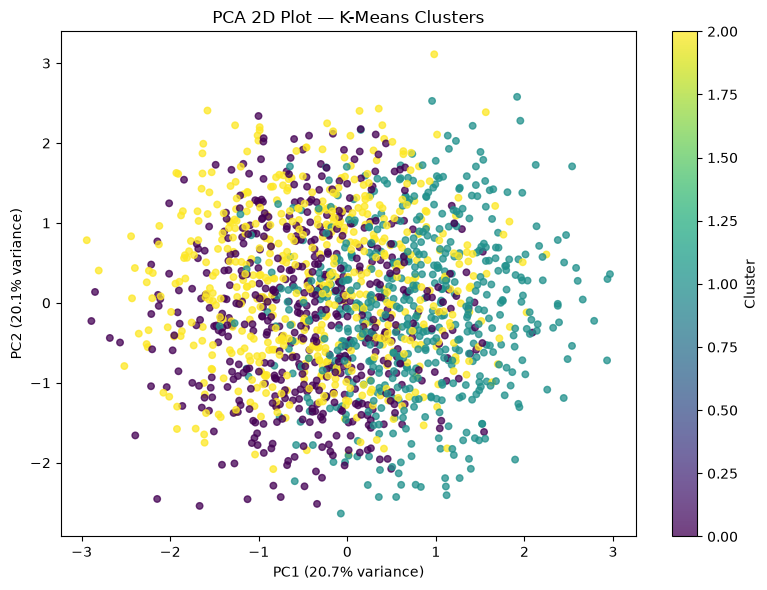

In [22]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, s=22, alpha=0.75)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA 2D Plot — K-Means Clusters")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

## 10. t-SNE visualization

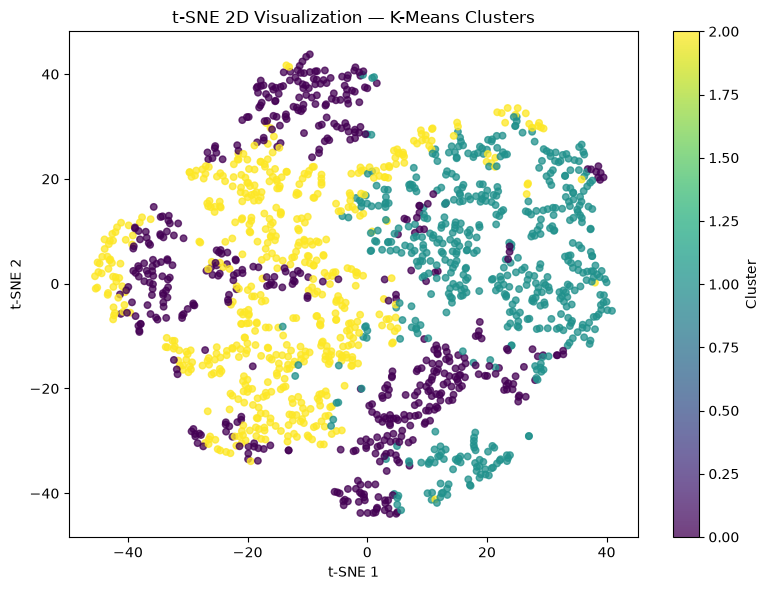

In [23]:
tsne = TSNE(n_components=2, perplexity=min(30, max(5, (len(X_scaled)-1)//3)),
            learning_rate="auto", init="pca", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, s=22, alpha=0.75)
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE 2D Visualization — K-Means Clusters")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [24]:
os.makedirs("../results", exist_ok=True)
clustered_df.to_csv("../results/kmeans_cluster_assignments.csv", index=False)
metrics.to_csv("../results/kmeans_metrics.csv", index=False)
print("Saved ../results/kmeans_cluster_assignments.csv")
print("Saved ../results/kmeans_metrics.csv")
display(metrics.round(4))

Saved ../results/kmeans_cluster_assignments.csv
Saved ../results/kmeans_metrics.csv


,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,3,0.1435,1.9446,273.3972
